# Business Analytics — Lab 2
## Classification: Predictive Maintenance

A company machines aluminium components on 12 CNC centres, three shifts a day.
An **unplanned stop** costs on average **9,000 EUR**. A **preventive intervention** between shifts costs
**600 EUR** and takes the machine out for 40 minutes.

The plant records sensor and process data at the end of every shift.
The question for us:

> *Given the state of a machine at the end of a shift, will it fail during
> the next one?*

This is a **binary classification** problem — but the business
question is not "is the model accurate?", it is **"what does the model save
us?"**.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, average_precision_score,
                             precision_recall_curve, accuracy_score,
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

RNG = np.random.default_rng(7)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 130)

## 1. The data

| variable | meaning |
|---|---|
| `machine_type` | A / B / C — three CNC families |
| `age_years` | age of the machine |
| `hours_since_maint` | hours run since last preventive maintenance |
| `tool_wear_min` | cumulated cutting minutes on the current tool |
| `vibration_rms` | spindle vibration, mm/s |
| `temp_bearing` | bearing temperature, °C |
| `torque_nm` | average torque |
| `rot_speed_rpm` | average spindle speed |
| `load_factor` | share of the shift under load |
| `night_shift` | 1 if night shift |
| **`failure`** | **target**: stop during the next shift |

In [5]:
df = pd.read_excel("/content/machine_failures.xlsx")
print(f"Dataset shape: {df.shape}")
df.describe()

Dataset shape: (12000, 11)


,age_years,hours_since_maint,tool_wear_min,vibration_rms,temp_bearing,torque_nm,rot_speed_rpm,load_factor,night_shift,failure
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,6.379946,208.626517,135.454133,2.293764,57.105850,39.981217,1503.183083,0.714355,0.501583,0.060917
std,3.141197,121.011191,56.413041,0.561529,4.431352,9.549244,261.675772,0.146474,0.500018,0.239187
min,0.200000,0.000000,0.000000,0.296000,43.000000,5.910000,497.000000,0.123000,0.000000,0.000000
25%,4.050000,103.775000,96.800000,1.921000,54.000000,33.497500,1329.000000,0.619000,0.000000,0.000000
50%,5.855000,207.300000,135.150000,2.287000,57.100000,40.080000,1502.000000,0.732000,1.000000,0.000000
75%,8.180000,312.925000,174.200000,2.673000,60.100000,46.390000,1677.000000,0.826000,1.000000,0.000000
max,18.000000,420.000000,355.500000,4.472000,74.800000,73.760000,2415.000000,0.996000,1.000000,1.000000


failure rate = 6.09%   (731 failures out of 12000)


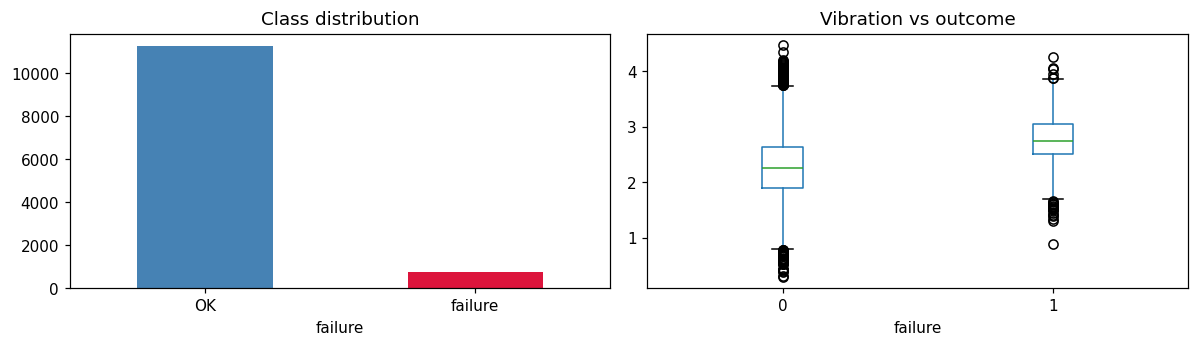

In [6]:
rate = df.failure.mean()
print(f"failure rate = {rate:.2%}   ({df.failure.sum()} failures out of {len(df)})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
df.failure.value_counts().plot.bar(ax=ax[0], color=["steelblue", "crimson"], rot=0)
ax[0].set_title("Class distribution"); ax[0].set_xticklabels(["OK", "failure"])
df.boxplot(column="vibration_rms", by="failure", ax=ax[1], grid=False)
ax[1].set_title("Vibration vs outcome"); ax[1].set_xlabel("failure")
plt.suptitle(""); plt.tight_layout(); plt.show()

> **6 failures in 100 shifts.** A model that always predicts "OK" is already
> ~94% accurate and completely worthless.

## 2. Train / test split and preprocessing

1. **The test set is touched once**, at the very end. Everything else
   (tuning, threshold selection) happens on training data via cross-validation.
2. **Preprocessing is fitted on the training set only** — otherwise the
   test set leaks into the scaler and your estimate is optimistic.
   A `Pipeline` enforces this automatically.

In [7]:
NUM = ["age_years", "hours_since_maint", "tool_wear_min", "vibration_rms",
       "temp_bearing", "torque_nm", "rot_speed_rpm", "load_factor"]
CAT = ["machine_type"]
PASS = ["night_shift"]

X = df[NUM + CAT + PASS]
y = df["failure"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=.30, stratify=y, random_state=0)   # stratify = keep 6% in both

print(f"train {X_tr.shape[0]} rows, failure rate {y_tr.mean():.2%}")
print(f"test  {X_te.shape[0]} rows, failure rate {y_te.mean():.2%}")

prep_scaled = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first"), CAT),
    ("pass", "passthrough", PASS),
])
prep_raw = ColumnTransformer([           # trees do not need scaling
    ("num", "passthrough", NUM),
    ("cat", OneHotEncoder(drop="first"), CAT),
    ("pass", "passthrough", PASS),
])

train 8400 rows, failure rate 6.10%
test  3600 rows, failure rate 6.08%


## 3. Metrics: why accuracy lies

A classifier makes two kinds of mistakes. Taking **"failure" as the positive class**:

| | **predicted: fail** (we intervene) | **predicted: OK** (we let it run) |
|---|---|---|
| **actual: fail** | **TP** — failure caught, 600 EUR | **FN** — unplanned stop, 9,000 EUR |
| **actual: OK** | **FP** — useless maintenance, 600 EUR | **TN** — nothing happens, 0 EUR |

Rows are what really happened, columns are what the model said.
The diagonal ($TP$, $TN$) is correct; the off-diagonal ($FP$, $FN$) are the errors —
and they do **not** cost the same: one missed failure costs as much as 15 unnecessary interventions.

With $TP, FP, TN, FN$ from the confusion matrix:

$$\text{accuracy}=\frac{TP+TN}{n}\qquad
  \text{precision}=\frac{TP}{TP+FP}\qquad
  \text{recall}=\frac{TP}{TP+FN}$$

- **Precision** = of the machines we stop, how many would really have failed?
  → controls **wasted maintenance**.
- **Recall** = of the machines that fail, how many did we catch?
  → controls **unplanned stops**.

These two pull in opposite directions. Which one matters more is a business
question, and the answer is driven by the 9,000 / 600 cost ratio.

In [8]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
print(f"'always OK' classifier -> accuracy on test: "
      f"{accuracy_score(y_te, dummy.predict(X_te)):.3f}")
print(f"                          recall on test:   "
      f"{recall_score(y_te, dummy.predict(X_te), zero_division=0):.3f}   <- catches nothing")

'always OK' classifier -> accuracy on test: 0.939
                          recall on test:   0.000   <- catches nothing


## 4. Logistic regression

$$\Pr(y=1 \mid x) = \sigma(\beta_0 + \beta^\top x), \qquad
  \sigma(t)=\frac{1}{1+e^{-t}}$$

Linear in the **log-odds**, so each coefficient has a clean reading:
$e^{\beta_j}$ is the multiplicative effect on the odds of failure for a
one-standard-deviation increase in $x_j$ (we standardised the inputs).

`class_weight="balanced"` re-weights the rare class so the fit is not
dominated by the 94% of healthy shifts.

In [9]:
logit = Pipeline([("prep", prep_scaled),
                  ("clf", LogisticRegression(max_iter=2000,
                                             class_weight="balanced"))]).fit(X_tr, y_tr)

names = logit.named_steps["prep"].get_feature_names_out()
coef = logit.named_steps["clf"].coef_[0]
odds = (pd.DataFrame({"feature": [n.split("__")[-1] for n in names],
                      "beta": coef.round(3),
                      "odds_ratio": np.exp(coef).round(2)})
        .sort_values("odds_ratio", ascending=False))
print(odds.to_string(index=False))

          feature   beta  odds_ratio
    vibration_rms  0.743        2.10
   machine_type_C  0.687        1.99
    tool_wear_min  0.680        1.97
        age_years  0.218        1.24
hours_since_maint  0.194        1.21
      night_shift  0.049        1.05
    rot_speed_rpm  0.040        1.04
   machine_type_B  0.042        1.04
        torque_nm  0.006        1.01
     temp_bearing -0.054        0.95
      load_factor -0.048        0.95


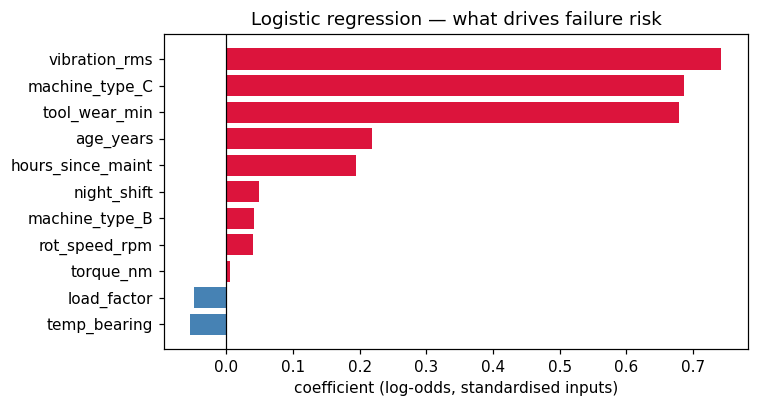

In [10]:
plt.figure(figsize=(7, 3.8))
o = odds.sort_values("beta")
plt.barh(o.feature, o.beta, color=np.where(o.beta > 0, "crimson", "steelblue"))
plt.axvline(0, color="k", lw=.8)
plt.xlabel("coefficient (log-odds, standardised inputs)")
plt.title("Logistic regression — what drives failure risk")
plt.tight_layout(); plt.show()

Look at `temp_bearing`: its coefficient may come out **negative**, even
though hot bearings genuinely raise the risk. The reason is that temperature
is itself generated by vibration and running hours, which are already in the
model. With correlated predictors, a single coefficient is *not* a causal
effect — it is the effect **holding the other variables fixed**, which may be
physically impossible.

Report coefficients as *associations*, never as levers to pull.

*"holding everything else constant, one extra standard deviation of
tool wear multiplies the odds of a stop by X"*. No other model on today's
list gives you a sentence like that.

## ROC-AUC / PR-AUC

Every metric so far needed a **threshold**. Accuracy, precision and recall
all change the moment you move the cut-off. So how do you compare two models
before you have chosen a cut-off for either?

Notice what a classifier really gives us: not a yes/no, but a **score** for
every shift. Sort the shifts by that score and you get a *priority list*

Both AUCs judge **only the order of the list**. They try every possible
cut-off at once and summarize the result in one number. That is their whole
purpose, and also their whole limitation: neither tells you where to cut.

The two differ in *what they count as a mistake*:

- **ROC-AUC** asks: how well are the failures separated from the healthy machines?
- **PR-AUC** asks: when we act on the top of the list, how often is the alarm real?

With 6% failures these two questions give very different answers.

### The ROC curve

Slide a threshold $t$ from 1.0 down to 0.0. Every shift with score $\ge t$ is
flagged. For each $t$ we fill in a confusion matrix and compute two rates,
one per **row** of the matrix:

$$\text{TPR} = \frac{TP}{TP+FN} \quad \text{(recall: of the machines that fail, how many did we flag?)}$$
$$\text{FPR} = \frac{FP}{FP+TN} \quad \text{(of the healthy machines, how many did we flag by mistake?)}$$

Each threshold gives one point $(\text{FPR}, \text{TPR})$. Joining them is
the **ROC curve**, and **ROC-AUC** is the area underneath.

How to read it:

- **Bottom-left $(0,0)$**: $t = 1$, we flag nobody. No false alarms, no catches.
- **Top-right $(1,1)$**: $t = 0$, we flag everybody. Every failure caught, every healthy machine disturbed.
- **Top-left $(0,1)$**: the ideal — every failure caught with zero false alarms.
  The closer the curve bends toward this corner, the better the ranking.
- **The diagonal**: a random score. Flag 30% of shifts at random and you catch
  30% of failures *and* disturb 30% of healthy machines. AUC = 0.5.

Moving $t$ down moves you **along** the curve; a better model **lifts the whole curve**.

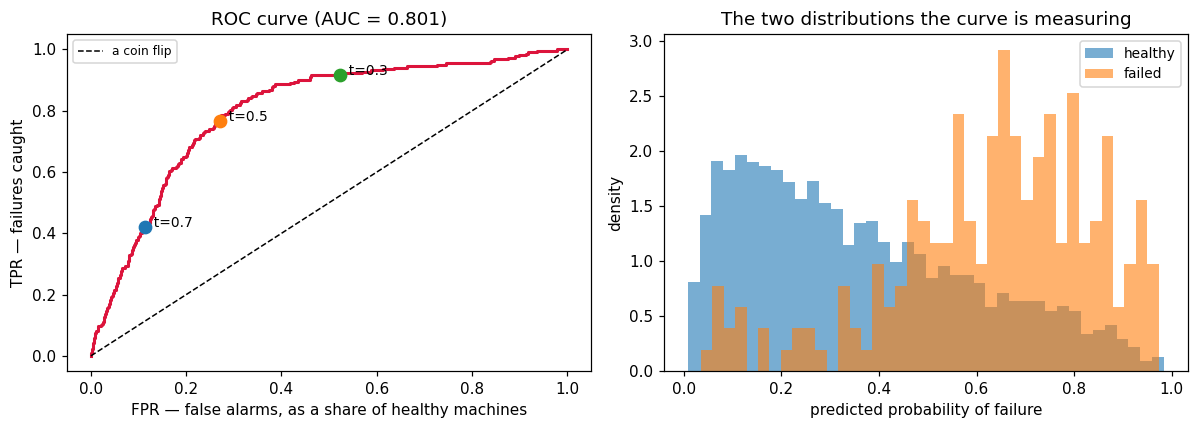

In [11]:
from sklearn.metrics import roc_curve, roc_auc_score

p_logit = logit.predict_proba(X_te)[:, 1]
fpr, tpr, thr = roc_curve(y_te, p_logit)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, lw=2, color="crimson")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="a coin flip")
for t in [0.7, 0.5, 0.3]:
    k = np.argmin(np.abs(thr - t))
    ax[0].plot(fpr[k], tpr[k], "o", ms=8)
    ax[0].annotate(f"  t={t}", (fpr[k], tpr[k]), fontsize=9)
ax[0].set_xlabel("FPR — false alarms, as a share of healthy machines")
ax[0].set_ylabel("TPR — failures caught")
ax[0].set_title(f"ROC curve (AUC = {roc_auc_score(y_te, p_logit):.3f})")
ax[0].legend(fontsize=8)

ax[1].hist(p_logit[y_te.values == 0], bins=40, alpha=.6, label="healthy", density=True)
ax[1].hist(p_logit[y_te.values == 1], bins=40, alpha=.6, label="failed", density=True)
ax[1].set_xlabel("predicted probability of failure")
ax[1].set_ylabel("density")
ax[1].set_title("The two distributions the curve is measuring")
ax[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

The right-hand panel is what ROC-AUC is really about: **how far apart the two
distributions are**. Perfectly separated → AUC 1.0. Completely overlapping →
AUC 0.5. Here they overlap a lot, and 0.80 is the honest summary of that.

### The definition worth memorising

> **ROC-AUC is the probability that a randomly chosen *failing* machine gets
> a higher score than a randomly chosen *healthy* one.**

This is not an analogy or a rough intuition — it is exactly what the area
equals. Let us check it by brute force: draw random pairs, one from each
class, and count how often the failing one scores higher.

In [12]:
rng = np.random.default_rng(0)
s_fail = p_logit[y_te.values == 1]
s_ok = p_logit[y_te.values == 0]

print(f"failing shifts {len(s_fail)}   healthy shifts {len(s_ok)}\n")
for N in [1_000, 10_000, 200_000]:
    i = rng.integers(0, len(s_fail), N)
    j = rng.integers(0, len(s_ok), N)
    wins = (s_fail[i] > s_ok[j]).sum() + 0.5 * (s_fail[i] == s_ok[j]).sum()
    print(f"  {N:>7,} random pairs  ->  {wins/N:.4f}")
print(f"\n  sklearn roc_auc_score      ->  {roc_auc_score(y_te, p_logit):.4f}")

failing shifts 219   healthy shifts 3381

    1,000 random pairs  ->  0.8030
   10,000 random pairs  ->  0.8031
  200,000 random pairs  ->  0.8020

  sklearn roc_auc_score      ->  0.8012


### Three consequences of the definition

1. **0.5 means useless.** A coin flip wins half the pairs by definition.
   An AUC *below* 0.5 means your model ranks correctly but you have the sign
   backwards.
2. **It ignores thresholds entirely.** It only cares about the *order* of the
   scores, not their values. Multiply every probability by 0.001 and the AUC
   does not move.
3. **A model can have a good AUC and be useless as deployed.** Which is
   exactly what happens to kNN in section 5: ROC-AUC 0.81, recall 0.00.
   The ranking is fine; the threshold is broken. Keep that example in mind —
   it is the clearest argument for separating the two questions.

### The PR curve

The fix is to build the curve from the two quantities a maintenance manager
actually feels — the ones from section 3:

$$\text{recall} = \frac{TP}{TP+FN} \quad \text{(of the failures, how many did we catch?)}$$
$$\text{precision} = \frac{TP}{TP+FP} \quad \text{(of the machines we stopped, how many were really failing?)}$$

Slide the threshold exactly as before, but now plot one point
$(\text{recall}, \text{precision})$ per threshold. That is the
**precision–recall (PR) curve**, and **PR-AUC** is the area underneath.

Notice that $TN$ appears **nowhere**. The thousands of healthy shifts we
correctly left alone — the cell that made FPR look so good — simply do not
count. PR is judged on the failures and on our alarms, nothing else.

How to read it:

- **Left end** (high threshold): we flag only the few most suspicious shifts.
  Low recall, and precision as high as the model can manage.
- **Right end** (low threshold): we flag everything. Recall 1, and precision
  falls to the share of failures in the data.
- **Top-right $(1,1)$**: the ideal — catch every failure, every alarm real.
- **The baseline is not 0.5.** A random score has precision equal to the
  failure rate at *every* threshold, so its curve is a flat line at **≈ 0.06**.

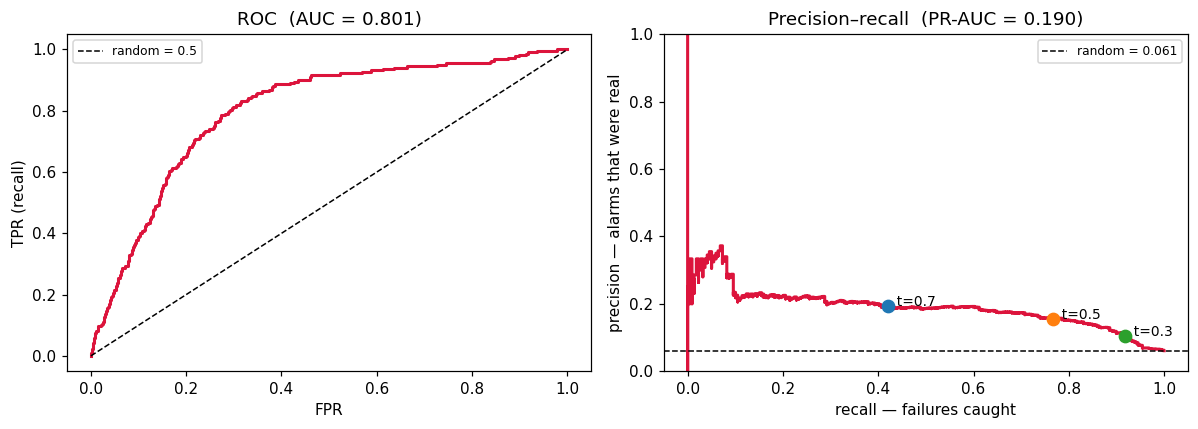

In [14]:
from sklearn.metrics import precision_recall_curve, average_precision_score

prec, rec, thr_pr = precision_recall_curve(y_te, p_logit)
base = y_te.mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, lw=2, color="crimson")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="random = 0.5")
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR (recall)")
ax[0].set_title(f"ROC  (AUC = {roc_auc_score(y_te, p_logit):.3f})")
ax[0].legend(fontsize=8)

ax[1].step(rec, prec, where="post", lw=2, color="crimson")
ax[1].axhline(base, color="k", ls="--", lw=1, label=f"random = {base:.3f}")
for t in [0.7, 0.5, 0.3]:
    k = np.argmin(np.abs(thr_pr - t))
    ax[1].plot(rec[k], prec[k], "o", ms=8)
    ax[1].annotate(f"  t={t}", (rec[k], prec[k]), fontsize=9)
ax[1].set_xlabel("recall — failures caught")
ax[1].set_ylabel("precision — alarms that were real")
ax[1].set_ylim(0, 1)
ax[1].set_title(f"Precision–recall  (PR-AUC = {average_precision_score(y_te, p_logit):.3f})")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Same model, same scores, same thresholds. On the left it looks good; on the
right it looks mediocre. Neither is wrong — they answer different questions.
The left says the failures *are* concentrated near the top of the list. The
right says that even near the top, most of the alarms are still false,
because the healthy machines outnumber the failing ones 15 to 1.
(The jagged left edge is just small numbers: with only a handful of alarms,
one hit or miss swings precision a lot.)


In [15]:
order = np.argsort(-p_logit)                 # the priority list, riskiest first
hit = y_te.values[order]                     # 1 where the machine really failed
precision_so_far = np.cumsum(hit) / np.arange(1, len(hit) + 1)

print("walking down the list:")
for k in [50, 100, 200, 475]:
    print(f"  top {k:>4}: {hit[:k].sum():>3} failures   precision {precision_so_far[k-1]:.3f}"
          f"   recall {hit[:k].sum() / hit.sum():.3f}")

print(f"\n  average of precision at each failure  ->  {precision_so_far[hit == 1].mean():.4f}")
print(f"  sklearn average_precision_score       ->  {average_precision_score(y_te, p_logit):.4f}")
print(f"  random model (= failure rate)         ->  {y_te.mean():.4f}")

walking down the list:
  top   50:  16 failures   precision 0.320   recall 0.073
  top  100:  22 failures   precision 0.220   recall 0.100
  top  200:  45 failures   precision 0.225   recall 0.205
  top  475:  92 failures   precision 0.194   recall 0.420

  average of precision at each failure  ->  0.1903
  sklearn average_precision_score       ->  0.1903
  random model (= failure rate)         ->  0.0608


### Reading the two numbers side by side

| | ROC-AUC | PR-AUC |
|---|---|---|
| random model | 0.50 | **failure rate ≈ 0.06** |
| perfect model | 1.00 | 1.00 |
| our logistic regression | ≈ 0.80 | ≈ 0.19 |
| uses $TN$? | yes (inside FPR) | **no** |
| changes if failures become rarer? | barely | **yes, drops** |

Two practical consequences:

1. **Never read PR-AUC against 0.5.** 0.19 looks terrible in absolute terms,
   but the baseline is 0.06: the model is roughly **3× better than chance**
   at making alarms real. Always quote PR-AUC *next to the failure rate*.
2. **Compare PR-AUC only on the same data.** Because the baseline is the
   failure rate, a PR-AUC from a plant with 2% failures and one from a plant
   with 20% are not comparable. ROC-AUC is (roughly) insensitive to that —
   which is exactly why it can hide the false-alarm problem.

Rule of thumb: when the positive class is **rare and the alarms are what you
pay for**, rank models by PR-AUC.

### Which metric answers which question

| metric | the question it answers | needs a threshold? | random model scores |
|---|---|---|---|
| accuracy | how often am I right? | yes — **useless at 6% positives** | 0.94 (say "never fails") |
| precision | of the machines I stopped, how many were really failing? | yes | ≈ 0.06 |
| recall / TPR | of the machines that failed, how many did I catch? | yes | whatever share you flag |
| **ROC-AUC** | does my ranking separate failures from healthy machines? | **no** | 0.50 |
| **PR-AUC** | when I act on the top of my ranking, how often is the alarm real? | **no** | ≈ 0.06 (failure rate) |
| expected cost | how many euros does this policy cost? | yes — and it **picks** it | — |

Use ROC-AUC to compare models, PR-AUC to compare them honestly when the
positive class is rare, and expected cost to decide what to actually do.

---
## Cross-validation

From the next section onward we start **tuning**: $k$ for kNN, the depth of a
tree. Every one of those is a knob, and every
knob needs a score to turn it against.

That score cannot come from the test set. Tune on the test set and it stops
being a test — you will have fitted your *choices* to it, and the number it
finally reports will be a flattering lie.

So we need a third thing, carved out of the training data.

### Why not just hold out one validation set?

You could. Split the training data 75/25, tune on the 25. The problem is that
the answer you get depends on *which rows landed in the 25*.

Here is the same model, the same data, and nothing changing but the random
seed of that split.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, KFold

scores_single = []
for seed in range(10):
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_tr, y_tr, test_size=.25, stratify=y_tr, random_state=seed)
    m = Pipeline([("prep", ColumnTransformer([
            ("num", StandardScaler(), NUM),
            ("cat", OneHotEncoder(drop="first"), CAT),
            ("pass", "passthrough", PASS)])),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(X_fit, y_fit)
    scores_single.append(average_precision_score(y_val, m.predict_proba(X_val)[:, 1]))

scores_single = np.array(scores_single)
print("PR-AUC on 10 different single validation splits:")
print(" ", np.round(scores_single, 3))
print(f"\n  min {scores_single.min():.3f}   max {scores_single.max():.3f}   "
      f"spread {scores_single.max()-scores_single.min():.3f}")

PR-AUC on 10 different single validation splits:
  [0.188 0.162 0.206 0.166 0.203 0.175 0.219 0.202 0.179 0.182]

  min 0.162   max 0.219   spread 0.057


### K-fold

Cut the training data into $K$ parts. Train on $K-1$, score on the one left
out, rotate, average.

```
fold 1   [ VAL ][ train ][ train ][ train ][ train ]
fold 2   [ train ][ VAL ][ train ][ train ][ train ]
fold 3   [ train ][ train ][ VAL ][ train ][ train ]
fold 4   [ train ][ train ][ train ][ VAL ][ train ]
fold 5   [ train ][ train ][ train ][ train ][ VAL ]
```

Every row is used for validation exactly once and for training $K-1$ times.
You pay for it in compute — $K$ fits instead of one — and you get back an
average plus, just as importantly, **a spread**.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# A random forest, borrowed from section 7 — here it is only a second model to
# put next to the first one, so that the comparison has something to compare.
rf_demo = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", NUM),
                                ("cat", OneHotEncoder(drop="first"), CAT),
                                ("pass", "passthrough", PASS)])),
    ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                   class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=0))])

for name, model in [("Logistic", logit), ("Random Forest", rf_demo)]:
    s = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"{name:14s} folds {np.round(s, 3)}   mean {s.mean():.3f} ± {s.std():.3f}")

Logistic       folds [0.204 0.169 0.244 0.196 0.184]   mean 0.199 ± 0.025
Random Forest  folds [0.316 0.303 0.321 0.311 0.24 ]   mean 0.298 ± 0.030


Now read those two lines as a decision, which is the whole point of having a
spread:

- Logistic ≈ 0.199 ± 0.025, Random Forest ≈ 0.302 ± 0.032.
- The gap is about 0.10, roughly **three standard deviations**. That
  difference is real; it is not the folds talking.

Had the two means differed by 0.02, with those same spreads, the honest
conclusion would have been *"we cannot tell these apart on this much data"* —
and the right next move would be to pick the simpler, cheaper, more
interpretable one rather than the one that won by noise.

> A model comparison without a spread is an opinion. Report mean ± std, or
> do not report a winner.

### The trap: what goes *inside* the fold

Cross-validation protects you only if **everything you learn from the data**
happens inside the loop. Scale before cross-validating and the scaler has
already seen the validation fold; your estimate comes back optimistic.

That is exactly why every model in this lab is a `Pipeline`:

```python
model = Pipeline([("prep", prep_scaled), ("clf", LogisticRegression())])
cross_val_score(model, X_tr, y_tr, cv=cv)   # prep is refitted inside each fold
```

With `StandardScaler` the damage is small. With feature selection, imputation
of missing values, or any resampling of the minority class, it is severe —
people routinely report cross-validated scores several points too high
because the selection happened once, outside, on all the data.

**Rule of thumb:** if a step looks at `y`, or at more than one row of `X`, it
belongs inside the pipeline.

## 5. k-nearest neighbours

No training phase: classify a point by majority vote among its $k$ closest
neighbours. Two things dominate its behaviour — **the distance metric**
(hence scaling) and **$k$** (small $k$ = high variance, large $k$ = high bias).

In [18]:
knn_scaled = Pipeline([("prep", prep_scaled),
                       ("clf", KNeighborsClassifier(n_neighbors=15))]).fit(X_tr, y_tr)
knn_raw = Pipeline([("prep", prep_raw),
                    ("clf", KNeighborsClassifier(n_neighbors=15))]).fit(X_tr, y_tr)

print(f"kNN  WITH scaling : ROC-AUC = {roc_auc_score(y_te, knn_scaled.predict_proba(X_te)[:,1]):.3f}")
print(f"kNN  NO   scaling : ROC-AUC = {roc_auc_score(y_te, knn_raw.predict_proba(X_te)[:,1]):.3f}")
print("\n-> without scaling, rot_speed_rpm (~1500) swamps vibration_rms (~2). "
      "Distance becomes meaningless.")

kNN  WITH scaling : ROC-AUC = 0.746
kNN  NO   scaling : ROC-AUC = 0.684

-> without scaling, rot_speed_rpm (~1500) swamps vibration_rms (~2). Distance becomes meaningless.


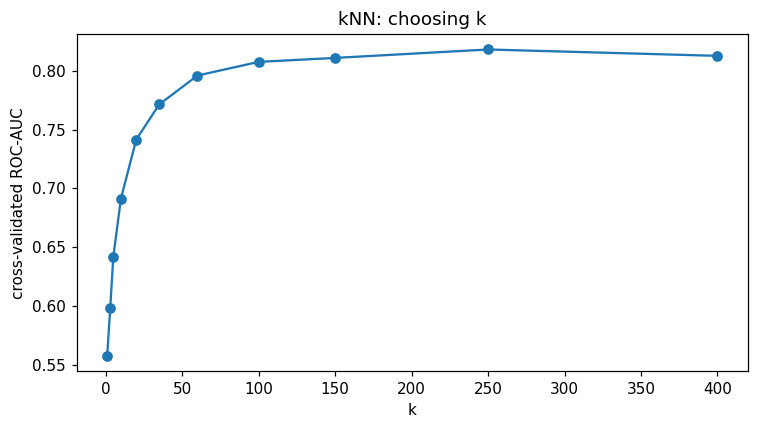

best k = 250
(250 neighbours, of which on average only 15 are failures)


In [19]:
ks = [1, 3, 5, 10, 20, 35, 60, 100, 150, 250, 400]
auc_k = []
for k in ks:
    pipe = Pipeline([("prep", prep_scaled), ("clf", KNeighborsClassifier(n_neighbors=k))])
    auc_k.append(cross_val_score(pipe, X_tr, y_tr, cv=StratifiedKFold(4),
                                 scoring="roc_auc").mean())
plt.plot(ks, auc_k, "o-")
plt.xlabel("k"); plt.ylabel("cross-validated ROC-AUC"); plt.title("kNN: choosing k")
plt.tight_layout(); plt.show()
best_k = ks[int(np.argmax(auc_k))]
print("best k =", best_k)
print(f"({best_k} neighbours, of which on average only "
      f"{best_k * y_tr.mean():.0f} are failures)")
knn = Pipeline([("prep", prep_scaled),
                ("clf", KNeighborsClassifier(n_neighbors=best_k))]).fit(X_tr, y_tr)

## 6. Decision tree

Recursively split the feature space to make the children as **pure** as
possible. With Gini impurity $G(S) = 1 - \sum_c p_c^2$, the split chosen is
the one maximising the impurity decrease.

Unpruned trees fit the training set perfectly and generalize badly — the
textbook picture of **overfitting**.

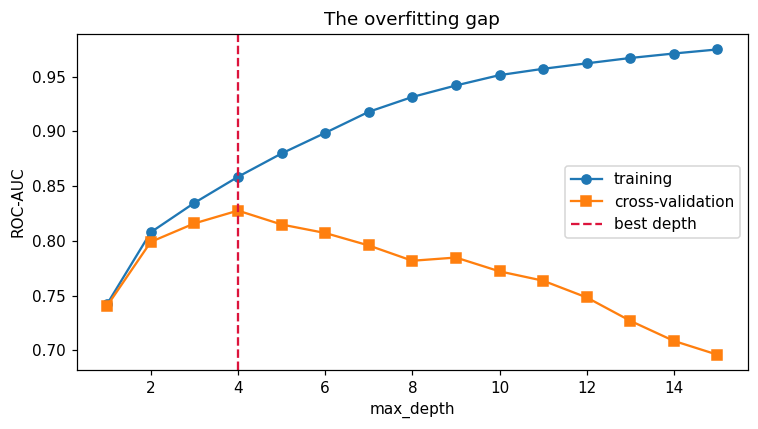

best depth = 4


In [20]:
depths = range(1, 16)
tr_auc, cv_auc = [], []
for dpt in depths:
    pipe = Pipeline([("prep", prep_raw),
                     ("clf", DecisionTreeClassifier(max_depth=dpt,
                                                    class_weight="balanced",
                                                    random_state=0))])
    pipe.fit(X_tr, y_tr)
    tr_auc.append(roc_auc_score(y_tr, pipe.predict_proba(X_tr)[:, 1]))
    cv_auc.append(cross_val_score(pipe, X_tr, y_tr, cv=StratifiedKFold(4),
                                  scoring="roc_auc").mean())

plt.plot(list(depths), tr_auc, "o-", label="training")
plt.plot(list(depths), cv_auc, "s-", label="cross-validation")
plt.axvline(list(depths)[int(np.argmax(cv_auc))], color="crimson", ls="--",
            label="best depth")
plt.xlabel("max_depth"); plt.ylabel("ROC-AUC"); plt.legend()
plt.title("The overfitting gap")
plt.tight_layout(); plt.show()

best_depth = list(depths)[int(np.argmax(cv_auc))]
print(f"best depth = {best_depth}")

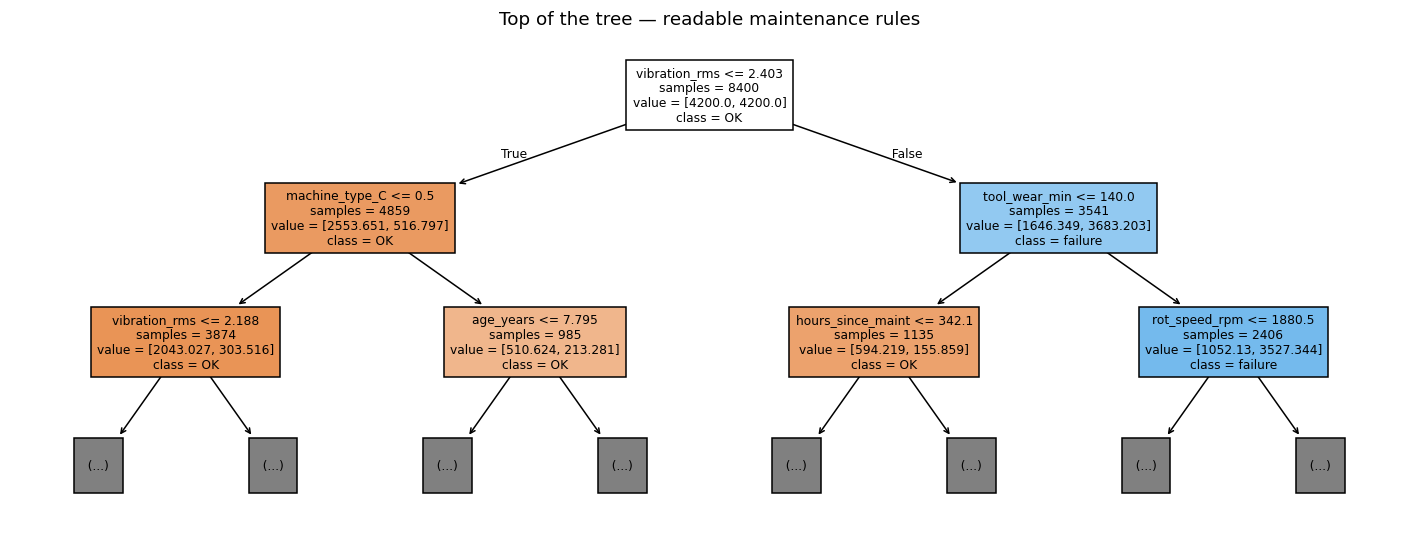

|--- vibration_rms <= 2.40
|   |--- machine_type_C <= 0.50
|   |   |--- vibration_rms <= 2.19
|   |   |   |--- truncated branch of depth 2
|   |   |--- vibration_rms >  2.19
|   |   |   |--- truncated branch of depth 2
|   |--- machine_type_C >  0.50
|   |   |--- age_years <= 7.80
|   |   |   |--- truncated branch of depth 2
|   |   |--- age_years >  7.80
|   |   |   |--- truncated branch of depth 2
|--- vibration_rms >  2.40
|   |--- tool_wear_min <= 140.00
|   |   |--- hours_since_maint <= 342.10
|   |   |   |--- truncated branch of depth 2
|   |   |--- hours_since_maint >  342.10
|   |   |   |--- truncated branch of depth 2
|   |--- tool_wear_min >  140.00
|   |   |--- rot_speed_rpm <= 1880.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- rot_speed_rpm >  1880.50
|   |   |   |--- truncated branch of depth 2



In [21]:
tree = Pipeline([("prep", prep_raw),
                 ("clf", DecisionTreeClassifier(max_depth=best_depth,
                                                class_weight="balanced",
                                                random_state=0))]).fit(X_tr, y_tr)

feat_names = [n.split("__")[-1] for n in tree.named_steps["prep"].get_feature_names_out()]

plt.figure(figsize=(13, 5))
plot_tree(tree.named_steps["clf"], max_depth=2, feature_names=feat_names,
          class_names=["OK", "failure"], filled=True, fontsize=8, impurity=False)
plt.title("Top of the tree — readable maintenance rules")
plt.tight_layout(); plt.show()

print(export_text(tree.named_steps["clf"], feature_names=feat_names,
                  max_depth=2, show_weights=False)[:900])

### Look closely at those thresholds

Compare the splits the tree chose with the rules we wrote into the simulator:

| split found by the tree | true rule in the process |
|---|---|
| `vibration_rms <= 2.40` | danger regime starts at 2.4 |
| `tool_wear_min <= 140.0` | ... combined with wear above 140 |
| `rot_speed_rpm <= 1880.5` | off-nominal beyond 1500 ± 380 |
| `machine_type_C` & `age > 7.8` | family C older than 8 years |

The tree recovered the physics almost exactly — and it did so without being
told that interactions or thresholds existed. That is precisely what trees
buy you over a linear model, and why the ensembles will win in section 9.

Those splits are also literally a **maintenance checklist**: "if tool wear
exceeds 140 min and vibration exceeds 2.4 mm/s, schedule an intervention".

## 7. Random forest

One tree is unstable. **Bagging** grows many trees on bootstrap samples, and
at each split considers only a random subset of features, then averages the
votes. Variance collapses; interpretability moves from *rules* to
*importances*.

In [22]:
rf = Pipeline([("prep", prep_raw),
               ("clf", RandomForestClassifier(n_estimators=400, max_depth=None,
                                              min_samples_leaf=3,
                                              class_weight="balanced_subsample",
                                              n_jobs=-1, random_state=0))]).fit(X_tr, y_tr)

print(f"single tree  ROC-AUC: {roc_auc_score(y_te, tree.predict_proba(X_te)[:,1]):.3f}")
print(f"random forest ROC-AUC: {roc_auc_score(y_te, rf.predict_proba(X_te)[:,1]):.3f}")

single tree  ROC-AUC: 0.817
random forest ROC-AUC: 0.838


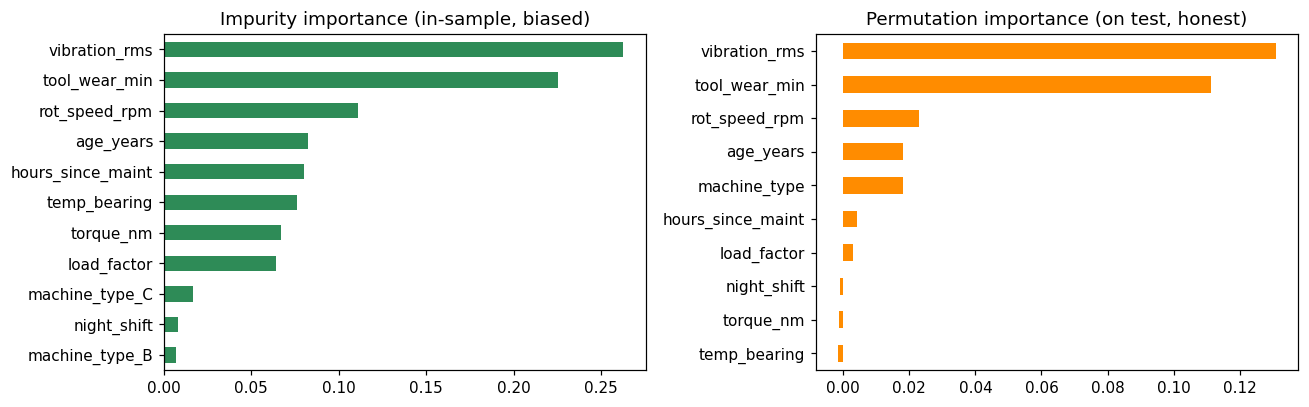

In [23]:
imp = pd.Series(rf.named_steps["clf"].feature_importances_,
                index=feat_names).sort_values()
perm = permutation_importance(rf, X_te, y_te, n_repeats=8, random_state=0,
                              scoring="roc_auc", n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_te.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
imp.plot.barh(ax=ax[0], color="seagreen"); ax[0].set_title("Impurity importance (in-sample, biased)")
perm_s.plot.barh(ax=ax[1], color="darkorange"); ax[1].set_title("Permutation importance (on test, honest)")
plt.tight_layout(); plt.show()

> Impurity importance favours high-cardinality continuous variables.
> When you report importances to a stakeholder, use **permutation importance**
> computed on held-out data.

## 8. Gradient boosting (XGBoost)

Boosting is sequential, not parallel: each new tree is fitted on the
**residual errors** of the current ensemble,
$F_{m}(x) = F_{m-1}(x) + \eta\, h_m(x)$, with learning rate $\eta$.
Shallow trees ("weak learners") are enough.

For imbalance, `scale_pos_weight` = #negatives / #positives.
`early_stopping_rounds` stops adding trees when the validation metric
stops improving.

In [24]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"scale_pos_weight = {spw:.1f}")

X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=.20,
                                              stratify=y_tr, random_state=1)

prep_x = prep_raw.fit(X_fit)
xgb_clf = XGBClassifier(
    n_estimators=600, learning_rate=0.06, max_depth=5,
    subsample=0.85, colsample_bytree=0.85, min_child_weight=3,
    reg_lambda=1.5, scale_pos_weight=spw,
    eval_metric="aucpr", early_stopping_rounds=40,
    n_jobs=-1, random_state=0,
)
xgb_clf.fit(prep_x.transform(X_fit), y_fit,
            eval_set=[(prep_x.transform(X_val), y_val)], verbose=False)
print(f"best iteration: {xgb_clf.best_iteration} of 600 "
      f"(early stopping saved {600 - xgb_clf.best_iteration} trees)")


class XGBWrapped:
    """Tiny wrapper so XGBoost behaves like the other pipelines."""
    def __init__(self, prep, clf): self.prep, self.clf = prep, clf
    def predict_proba(self, X): return self.clf.predict_proba(self.prep.transform(X))
    def predict(self, X): return self.clf.predict(self.prep.transform(X))


xgb = XGBWrapped(prep_x, xgb_clf)
print(f"XGBoost ROC-AUC: {roc_auc_score(y_te, xgb.predict_proba(X_te)[:,1]):.3f}")

scale_pos_weight = 15.4
best iteration: 52 of 600 (early stopping saved 548 trees)
XGBoost ROC-AUC: 0.839


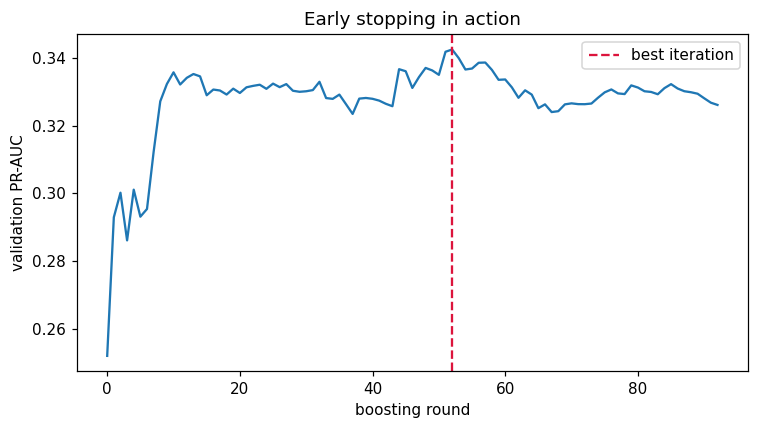

In [25]:
hist = xgb_clf.evals_result()["validation_0"]["aucpr"]
plt.plot(hist)
plt.axvline(xgb_clf.best_iteration, color="crimson", ls="--", label="best iteration")
plt.xlabel("boosting round"); plt.ylabel("validation PR-AUC"); plt.legend()
plt.title("Early stopping in action")
plt.tight_layout(); plt.show()

## 9. Model comparison

With 6% positives, the ROC curve is flattering. The
**precision–recall curve** and its area (PR-AUC / average precision) are the
honest picture for a rare event: the baseline of PR-AUC is the positive rate
itself (0.06), not 0.5.

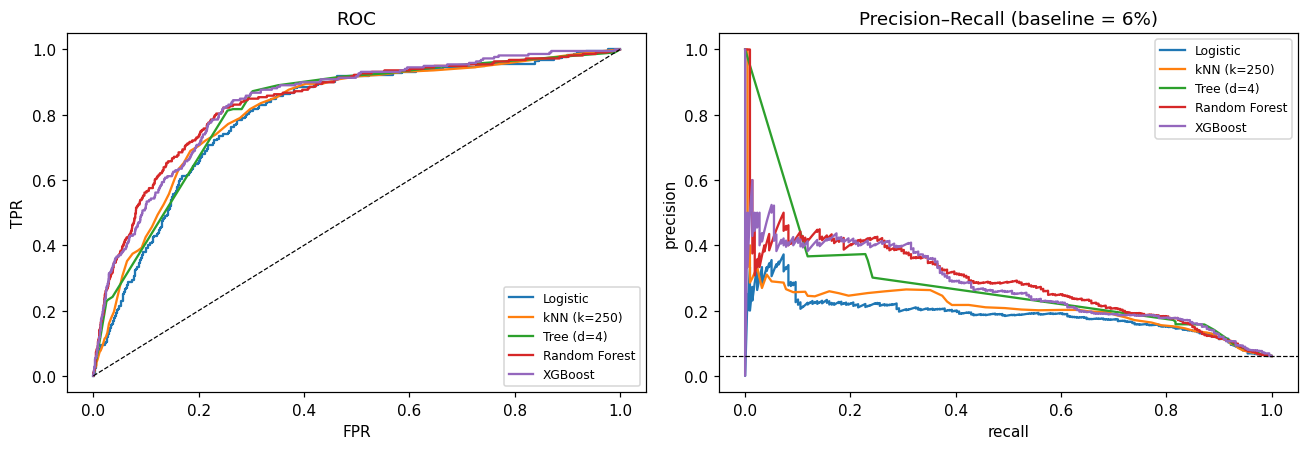

               accuracy  precision  recall     f1  roc_auc  pr_auc
model                                                             
Logistic          0.733      0.156   0.767  0.259    0.801   0.190
kNN (k=250)       0.939      0.000   0.000  0.000    0.813   0.208
Tree (d=4)        0.733      0.163   0.817  0.272    0.817   0.207
Random Forest     0.935      0.423   0.187  0.259    0.838   0.289
XGBoost           0.772      0.182   0.785  0.295    0.839   0.278


In [37]:
models = {"Logistic": logit, f"kNN (k={best_k})": knn,
          f"Tree (d={best_depth})": tree, "Random Forest": rf, "XGBoost": xgb}

rows = []
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, mdl in models.items():
    pr = mdl.predict_proba(X_te)[:, 1]
    yh = (pr >= .5).astype(int)
    rows.append(dict(model=name,
                     accuracy=accuracy_score(y_te, yh),
                     precision=precision_score(y_te, yh, zero_division=0),
                     recall=recall_score(y_te, yh, zero_division=0),
                     f1=f1_score(y_te, yh, zero_division=0),
                     roc_auc=roc_auc_score(y_te, pr),
                     pr_auc=average_precision_score(y_te, pr)))
    fpr, tpr, _ = roc_curve(y_te, pr)
    ax[0].plot(fpr, tpr, label=name)
    p_, r_, _ = precision_recall_curve(y_te, pr)
    ax[1].plot(r_, p_, label=name)

ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
ax[0].set_title("ROC"); ax[0].legend(fontsize=8)
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=.8)
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision–Recall (baseline = 6%)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

comp = pd.DataFrame(rows).set_index("model").round(3)
print(comp.to_string())

Read the table row by row and notice two traps.

1. **Accuracy is highest for the worst models.** kNN reaches ~94% accuracy
   with recall 0.00: with $k$ large and only 6% positives, the majority vote
   among neighbours is *never* "failure", so no observation ever crosses 0.5.
   The model is not broken — the **threshold** is. Its ROC-AUC shows it does
   rank machines by risk.
2. **The ranking depends on the metric.** On PR-AUC the two ensembles are
   clearly ahead; the logistic model and the single tree lag, because the
   true risk here lives in interactions and regimes that a linear model
   cannot express and one shallow tree cannot cover.


## From probabilities to a decision: the 0.5 threshold is arbitrary

Every classifier outputs a probability. The 0.5 cut-off assumes a false
positive and a false negative cost the same. Instead we can calculate:


$$\text{Expected cost}(t) = \underbrace{FN(t) \cdot 9000}_{\text{missed stop}}
 + \underbrace{FP(t)\cdot 600}_{\text{useless intervention}}
 + \underbrace{TP(t)\cdot 600}_{\text{intervention that paid off}}$$

We sweep $t$ and pick the minimum

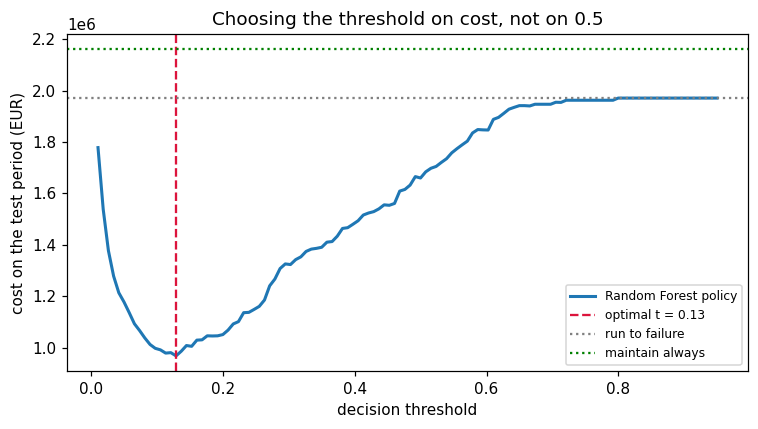

best model by PR-AUC: Random Forest

run to failure        :  1,971,000 EUR
maintain always       :  2,160,000 EUR
model @ t = 0.50      :  1,660,200 EUR
model @ t = 0.13 (opt) :    968,400 EUR

saving vs run-to-failure: 1,002,600 EUR over 3600 shifts (278 EUR per shift)


In [27]:
C_FAIL, C_MAINT = 9000, 600

def expected_cost(y_true, proba, t):
    yh = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yh, labels=[0, 1]).ravel()
    return fn * C_FAIL + (fp + tp) * C_MAINT

ts = np.linspace(0.01, 0.95, 120)
best_model = comp["pr_auc"].idxmax()
proba_te = models[best_model].predict_proba(X_te)[:, 1]
costs = np.array([expected_cost(y_te, proba_te, t) for t in ts])
t_star = ts[costs.argmin()]

do_nothing = y_te.sum() * C_FAIL                   # run to failure
always_maint = len(y_te) * C_MAINT                 # service every machine every shift

plt.plot(ts, costs, lw=2, label=f"{best_model} policy")
plt.axvline(t_star, color="crimson", ls="--", label=f"optimal t = {t_star:.2f}")
plt.axhline(do_nothing, color="grey", ls=":", label="run to failure")
plt.axhline(always_maint, color="green", ls=":", label="maintain always")
plt.xlabel("decision threshold"); plt.ylabel("cost on the test period (EUR)")
plt.legend(fontsize=8); plt.title("Choosing the threshold on cost, not on 0.5")
plt.tight_layout(); plt.show()

print(f"best model by PR-AUC: {best_model}\n")
print(f"run to failure        : {do_nothing:>10,.0f} EUR")
print(f"maintain always       : {always_maint:>10,.0f} EUR")
print(f"model @ t = 0.50      : {expected_cost(y_te, proba_te, .50):>10,.0f} EUR")
print(f"model @ t = {t_star:.2f} (opt) : {expected_cost(y_te, proba_te, t_star):>10,.0f} EUR")
saving = do_nothing - costs.min()
print(f"\nsaving vs run-to-failure: {saving:,.0f} EUR over {len(y_te)} shifts "
      f"({saving/len(y_te):,.0f} EUR per shift)")

In [28]:
yh = (proba_te >= t_star).astype(int)
cm = confusion_matrix(y_te, yh)
print(f"Confusion matrix at t = {t_star:.2f}\n")
print(pd.DataFrame(cm, index=["actual OK", "actual FAIL"],
                   columns=["pred OK", "pred FAIL"]).to_string())
print("\n" + classification_report(y_te, yh, target_names=["OK", "failure"],
                                   zero_division=0))

Confusion matrix at t = 0.13

             pred OK  pred FAIL
actual OK       2588        793
actual FAIL       43        176

              precision    recall  f1-score   support

          OK       0.98      0.77      0.86      3381
     failure       0.18      0.80      0.30       219

    accuracy                           0.77      3600
   macro avg       0.58      0.78      0.58      3600
weighted avg       0.93      0.77      0.83      3600



The optimal threshold sits well below 0.5, because missing
a failure costs 15 times more than an unnecessary intervention. The model is
deliberately made *trigger-happy*: low precision is acceptable, low recall is not.

Notice also what the two flat lines mean. They are the **two policies that
need no analytics at all**. A model only earns its budget if it beats both.

---
# Supplement — What do you do when you have no labels?

Everything above rests on one asset: **731 labelled failures**. We

Now consider the situation the same company faces next quarter:

> A new CNC family arrives. A line is instrumented for the first time.
> A plant in another country starts sending data.
>
> **Zero labelled failures.** You cannot train any of the six models above.

You still have sensor data, and you still have the 9,000 EUR stoppage. What
can you do on day one?

## Anomaly detection — and the trap in its name

The idea: learn what *normal* looks like, then flag whatever departs from it.
No labels needed.

> **"Anomalous" means statistically unusual. "Failure" is a business event.
> They are not the same thing.**

A machine can sit in a perfectly ordinary operating state and break. A
machine can run in a very unusual state — new tooling, an odd product mix,
a hot afternoon — and be completely fine.

Anomaly detection *assumes* that rare equals bad. Supervised learning
*learns* what bad looks like. That difference is worth money, and in this
supplement we are going to measure exactly how much.

In [41]:
from sklearn.svm import OneClassSVM

# This block is self-contained: it only needs X_tr/X_te/y_tr/y_te and the
# `logit` and `rf` pipelines fitted earlier.
prep_ad = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first"), CAT),
    ("pass", "passthrough", PASS),
]).fit(X_tr)

Z_tr = prep_ad.transform(X_tr)
Z_te = prep_ad.transform(X_te)
Z_tr_ok = Z_tr[y_tr.values == 0]          # healthy shifts only

print(f"all training shifts   {Z_tr.shape[0]}")
print(f"healthy shifts only   {Z_tr_ok.shape[0]}")
print(f"test shifts           {Z_te.shape[0]}   (failure rate {y_te.mean():.1%})")

all training shifts   8400
healthy shifts only   7888
test shifts           3600   (failure rate 6.1%)


## One-Class SVM

Fit a boundary that encloses the bulk of the data in a kernel feature space.
`nu` is roughly the fraction of training points allowed outside the boundary;
`gamma` sets how wiggly the boundary may be.

It is the method everyone names first. Let us see whether it earns that.

In [31]:
import time

rows = []
for nu in [0.01, 0.05, 0.10, 0.25]:
    for gamma in ["scale", 0.05, 0.2]:
        t0 = time.time()
        oc = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(Z_tr_ok)
        ap = average_precision_score(y_te, -oc.score_samples(Z_te))
        rows.append(dict(nu=nu, gamma=str(gamma), pr_auc=round(ap, 3),
                         seconds=round(time.time() - t0, 1)))
ocsvm_grid = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
print(ocsvm_grid.to_string(index=False))

best = ocsvm_grid.iloc[0]
print(f"\nbest One-Class SVM: PR-AUC {best.pr_auc}")
print(f"Isolation Forest, no tuning at all: "
      f"PR-AUC {average_precision_score(y_te, s_ok):.3f}")

  nu gamma  pr_auc  seconds
0.25  0.05   0.087      1.4
0.25 scale   0.086      1.4
0.25   0.2   0.086      1.4
0.10  0.05   0.081      0.5
0.10 scale   0.081      0.6
0.10   0.2   0.081      0.5
0.05   0.2   0.079      0.3
0.05 scale   0.078      0.3
0.01   0.2   0.077      0.2
0.05  0.05   0.076      0.3
0.01 scale   0.071      0.1
0.01  0.05   0.070      0.1

best One-Class SVM: PR-AUC 0.087
Isolation Forest, no tuning at all: PR-AUC 0.102


**Twelve fits to lose to a default.** The Isolation Forest beats every cell
of that grid, out of the box and in a fraction of the time.

This is worth saying out loud because the instinct runs the other way: the
method with the more impressive name is not the better tool. On tabular data
of this size, Isolation Forest is the sensible first thing to reach for, and
One-Class SVM is what you try when it fails.

In [32]:
oc_best = OneClassSVM(kernel="rbf", nu=float(best.nu),
                      gamma=(best.gamma if best.gamma == "scale" else float(best.gamma))
                      ).fit(Z_tr_ok)
s_oc = -oc_best.score_samples(Z_te)

## The comparison that matters

Put the label-free detectors next to the supervised models from Part 1.
Same test set, same metric.

In [38]:
scores = {
    "random guessing":              np.zeros(len(y_te)),
    "One-Class SVM (tuned)":        s_oc,
    #"Isolation Forest (outlier)":   s_all,
    #"Isolation Forest (novelty)":   s_ok,
    "Logistic  [uses labels]":      logit.predict_proba(X_te)[:, 1],
    "Random Forest  [uses labels]": rf.predict_proba(X_te)[:, 1],
}

tab = pd.DataFrame([
    dict(method=k,
         roc_auc=0.5 if k == "random guessing" else roc_auc_score(y_te, v),
         pr_auc=y_te.mean() if k == "random guessing" else average_precision_score(y_te, v))
    for k, v in scores.items()]).set_index("method").round(3)
print(tab.to_string())

                              roc_auc  pr_auc
method                                       
random guessing                 0.500   0.061
One-Class SVM (tuned)           0.614   0.087
Logistic  [uses labels]         0.801   0.190
Random Forest  [uses labels]    0.838   0.289


top decile failure rate : 12.8%
bottom decile           : 3.3%
base rate               : 6.1%


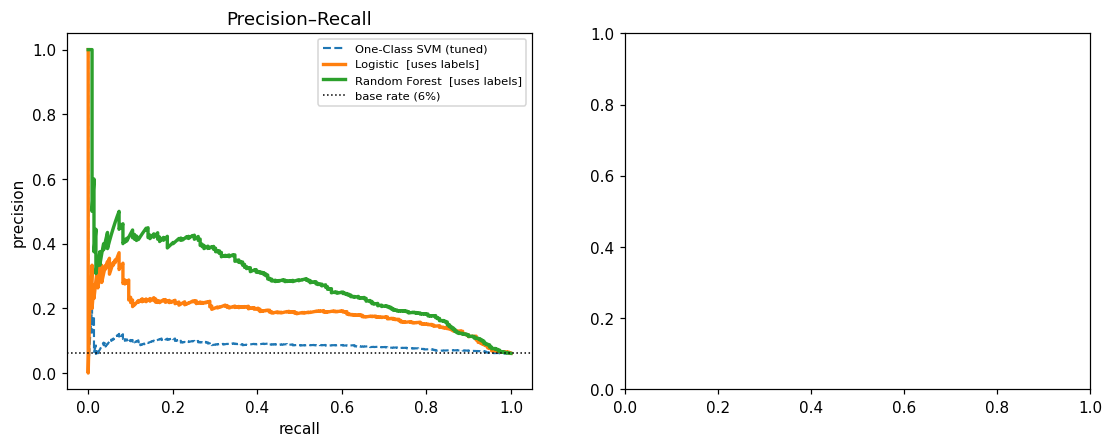

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for k, v in scores.items():
    if k == "random guessing":
        continue
    style = dict(lw=2.2) if "labels" in k else dict(lw=1.4, ls="--")
    p_, r_, _ = precision_recall_curve(y_te, v)
    ax[0].plot(r_, p_, label=k, **style)
ax[0].axhline(y_te.mean(), color="k", ls=":", lw=1, label="base rate (6%)")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
ax[0].set_title("Precision–Recall"); ax[0].legend(fontsize=7.5)

# decile lift: sort the test shifts by suspicion, look at the failure rate
#dec = pd.DataFrame({"score": s_ok, "fail": y_te.values})
#dec["decile"] = pd.qcut(dec.score, 10, labels=False, duplicates="drop")
#lift = dec.groupby("decile").fail.mean() * 100
#ax[1].bar(lift.index + 1, lift.values, color="steelblue")
#ax[1].axhline(y_te.mean() * 100, color="crimson", ls="--", label="base rate")
#ax[1].set_xlabel("decile by anomaly score (10 = most suspect)")
#ax[1].set_ylabel("actual failure rate (%)")
#ax[1].set_title("Isolation Forest: does the ranking mean anything?")
#ax[1].legend(fontsize=8)
#plt.tight_layout()
#plt.show()

print(f"top decile failure rate : {lift.iloc[-1]:.1f}%")
print(f"bottom decile           : {lift.iloc[0]:.1f}%")
print(f"base rate               : {y_te.mean()*100:.1f}%")

The ranking is **not** noise: the most-suspect decile fails well above the
base rate, the least-suspect well below. Without a single label, the method
has found something real.

And it is still nowhere near what the labels buy you. Time to put that in euros.

## What are the labels worth?

Reuse the cost structure from Part 1 — 9,000 EUR a stoppage, 600 EUR an
intervention — and give every method the same courtesy we gave the Random
Forest: pick its best threshold.

In [35]:
C_FAIL, C_MAINT = 9000, 600

def cheapest_policy(score):
    """Minimum expected cost over all thresholds, and the threshold achieving it."""
    s = (score - score.min()) / (score.max() - score.min() + 1e-12)
    best = (np.inf, None)
    for t in np.linspace(0.01, 0.99, 200):
        tn, fp, fn, tp = confusion_matrix(y_te, (s >= t).astype(int), labels=[0, 1]).ravel()
        c = fn * C_FAIL + (fp + tp) * C_MAINT
        if c < best[0]:
            best = (c, t)
    return best

run_to_failure = y_te.sum() * C_FAIL
maintain_always = len(y_te) * C_MAINT

policies = {
    "run to failure":                 run_to_failure,
    "maintain always":                maintain_always,
    "One-Class SVM (no labels)":      cheapest_policy(s_oc)[0],
    "Isolation Forest (no labels)":   cheapest_policy(s_ok)[0],
    "Logistic (labels)":              cheapest_policy(scores["Logistic  [uses labels]"])[0],
    "Random Forest (labels)":         cheapest_policy(scores["Random Forest  [uses labels]"])[0],
}
cost_tab = pd.DataFrame({"cost_EUR": pd.Series(policies).round(0)})
cost_tab["saving_vs_run_to_failure"] = (run_to_failure - cost_tab.cost_EUR).round(0)
print(cost_tab.to_string())

gap = policies["Isolation Forest (no labels)"] - policies["Random Forest (labels)"]
print(f"\nvalue of having labels : {gap:,.0f} EUR over {len(y_te)} shifts")
print(f"labelled failures used : {int(y_tr.sum())}")
print(f"  -> roughly {gap/y_tr.sum():,.0f} EUR per labelled failure")

                              cost_EUR  saving_vs_run_to_failure
run to failure                 1971000                         0
maintain always                2160000                   -189000
One-Class SVM (no labels)      1704000                    267000
Isolation Forest (no labels)   1590600                    380400
Logistic (labels)              1083600                    887400
Random Forest (labels)          961800                   1009200

value of having labels : 628,800 EUR over 3600 shifts
labelled failures used : 512
  -> roughly 1,228 EUR per labelled failure


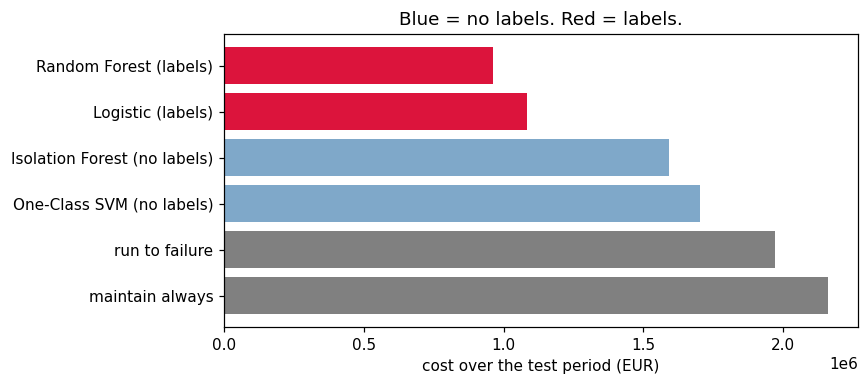

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = ["maintain always", "run to failure", "One-Class SVM (no labels)",
         "Isolation Forest (no labels)", "Logistic (labels)", "Random Forest (labels)"]
cols = ["grey", "grey", "#7FA8C9", "#7FA8C9", "crimson", "crimson"]
ax.barh(order, [policies[k] for k in order], color=cols)
ax.set_xlabel("cost over the test period (EUR)")
ax.set_title("Blue = no labels. Red = labels.")
plt.tight_layout()
plt.show()